# Assignment 2 · Household object classification
Alina Kovalenko · ST-2402

This notebook trains the CNN from Assignment 1 and a MobileNetV4 transfer classifier on the same four classes. Both use the same training, validation and test photos. The final cells compare their predictions and save the trained Keras models.

**Run in Colab.** Open this notebook, connect to a runtime (GPU recommended), then run the cells in order. Allow access to Google Drive. Set `DATA_DIR` to the folder with `train`, `val` and `test` if it differs from the Assignment 1 location. The notebook downloads public ImageNet weights automatically. The final cell saves the models and metrics to My Drive.

## Load the dataset

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import hashlib
import json
from PIL import Image, ImageOps, ImageDraw
from IPython.display import display

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    ConfusionMatrixDisplay
)

SEED = 2
IMG_SIZE = (224, 224)
BATCH_SIZE = 16

CLASS_NAMES = ['bottles', 'cups', 'pens', 'scissors']
SPLITS = ['train', 'val', 'test']
N_CLASSES = len(CLASS_NAMES)

keras.utils.set_random_seed(SEED)

print('TensorFlow version:', tf.__version__)
print('Available GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.21.0
Available GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
try:
    from google.colab import drive
except ImportError:
    PROJECT_DIR = Path.cwd()
    DATA_DIR = Path('data/prepared')
else:
    drive.mount('/content/drive')
    PROJECT_DIR = Path('/content/drive/MyDrive/ObjectLab')
    DATA_DIR = Path('/content/drive/MyDrive/Computer vision dataset')

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f'Set DATA_DIR to the folder with train, val and test: {DATA_DIR}')
print('Dataset folder:', DATA_DIR.name)

Mounted at /content/drive
Dataset folder: Computer vision dataset


The Assignment 2 dataset contains 623 reviewed images. The next cell skips the 22 duplicate paths identified in the original Drive folders and verifies the remaining files against the recorded split.

In [3]:
def read_rgb(path):
    with Image.open(path) as image:
        return ImageOps.exif_transpose(image).convert('RGB')

# These reviewed duplicates may already have been removed from Drive.
excluded = set('''
train/bottles/photo_5426963673156099991_x.jpg
train/bottles/photo_5426963673156099992_y.jpg
train/bottles/photo_5426963673156099995_y.jpg
train/bottles/photo_5426963673156099997_y.jpg
train/bottles/photo_5426963673156100004_y.jpg
train/bottles/photo_5426963673156100011_y.jpg
train/bottles/photo_5426963673156100012_x.jpg
train/bottles/photo_5426963673156100013_y.jpg
train/cups/photo_5426963673156099934_x.jpg
train/cups/photo_5426963673156099937_y.jpg
train/cups/photo_5426963673156099938_y.jpg
train/cups/photo_5426963673156099940_x.jpg
train/cups/photo_5426963673156099942_y.jpg
train/pens/photo_5426963673156100071_y.jpg
train/pens/photo_5426963673156100097_x.jpg
train/scissors/31.jpg
train/scissors/32.jpg
train/scissors/photo_5426963673156100137_x.jpg
train/scissors/photo_5426963673156100138_y.jpg
val/cups/96.jpg
val/scissors/photo_5426963673156100174_y.jpg
train/scissors/photo_5426963673156100143_x(1).jpg
'''.split())
file_hashes = []

records = []
extensions = ['.jpg', '.jpeg', '.png', '.webp', '.bmp']

for split in SPLITS:
    for label, class_name in enumerate(CLASS_NAMES):
        folder = DATA_DIR / split / class_name
        for path in sorted(folder.iterdir()):
            if path.suffix.lower() not in extensions:
                continue
            relative = path.relative_to(DATA_DIR).as_posix()
            if relative in excluded:
                continue
            file_hashes.append(relative + ' ' + hashlib.sha256(path.read_bytes()).hexdigest())
            image = read_rgb(path)
            records.append({'path': relative, 'split': split, 'class_name': class_name, 'label': label, 'width': image.width, 'height': image.height})

fingerprint = hashlib.sha256('\n'.join(sorted(file_hashes)).encode()).hexdigest()
if fingerprint != '86bb7625fa4455e0f40f40cc2d4837b7f4fc2cf1eed409b4b733649a5cf86458':
    raise ValueError(f'Found {len(records)} photos. Check DATA_DIR against the reviewed 623-image Assignment 2 split.')
df = pd.DataFrame(records)

counts = pd.crosstab(df['class_name'], df['split']).reindex(index=CLASS_NAMES, columns=SPLITS, fill_value=0)

display(counts)
print('Total number of images:', len(df))

split,train,val,test
class_name,,,
bottles,113,21,20
cups,113,20,20
pens,120,21,21
scissors,115,19,20


Total number of images: 623


**Data Preprocessing**

This step preprocesses the images before model training. All images are converted to RGB format and resized to 224 × 224 pixels while preserving their original aspect ratio using padding. The images are then separated into the predefined training, validation, and test sets and converted into TensorFlow datasets. Data augmentation, including horizontal flipping, small rotations, and contrast changes, is applied only to the training images to increase their variability. Finally, the code visualizes the class distribution, sample training images, and examples of augmented images.

In [4]:
def prepare_image(path):
    image = read_rgb(path)
    image = ImageOps.pad(image, IMG_SIZE, method=Image.Resampling.LANCZOS, color=(127, 127, 127))
    return np.asarray(image, dtype=np.uint8)

X = np.empty((len(df), IMG_SIZE[1], IMG_SIZE[0], 3), dtype=np.uint8)

for i, row in enumerate(df.itertuples(index=False)):
    X[i] = prepare_image(DATA_DIR / row.path)

y = df['label'].to_numpy(dtype=np.int32)

arrays = {}

for split in SPLITS:
    mask = df['split'].eq(split).to_numpy()
    arrays[split] = (X[mask], y[mask])
    print(split, arrays[split][0].shape)

X_train, y_train = arrays['train']
X_val, y_val = arrays['val']
X_test, y_test = arrays['test']

train (461, 224, 224, 3)
val (81, 224, 224, 3)
test (81, 224, 224, 3)


In [5]:
def make_dataset(images, labels, training=False):
    ds = tf.data.Dataset.from_tensor_slices((images, labels))
    if training:
        ds = ds.shuffle(len(images), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE)

val_ds = make_dataset(X_val, y_val)
test_ds = make_dataset(X_test, y_test)

def make_augmentation():
    return keras.Sequential([
        layers.RandomFlip('horizontal', seed=SEED),
        layers.RandomRotation(0.05, fill_mode='constant', fill_value=127, seed=SEED + 1),
        layers.RandomContrast(0.10, seed=SEED + 2)
    ], name='augmentation')

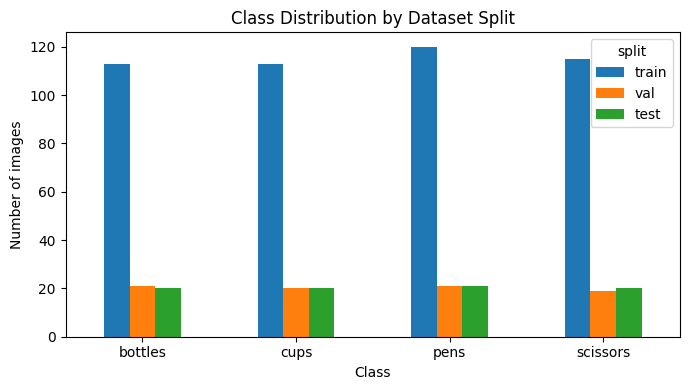

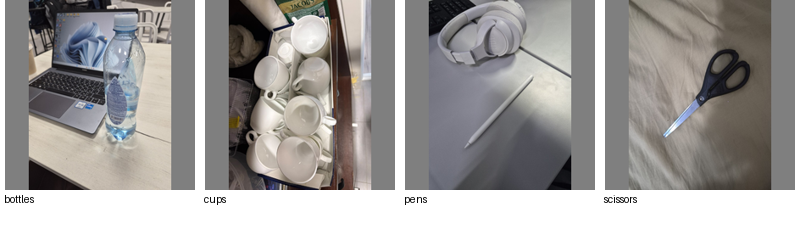

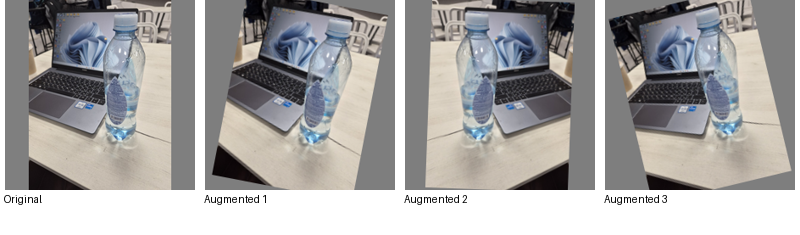

In [6]:
def show_images(images, titles, cols=4):
    tile_w, tile_h = 200, 235
    rows = int(np.ceil(len(images) / cols))
    sheet = Image.new('RGB', (cols * tile_w, rows * tile_h), 'white')
    draw = ImageDraw.Draw(sheet)
    for i, (image, title) in enumerate(zip(images, titles)):
        image = Image.fromarray(np.clip(image, 0, 255).astype('uint8'))
        thumb = ImageOps.contain(image, (190, 190))
        x = (i % cols) * tile_w
        y = (i // cols) * tile_h
        sheet.paste(thumb, (x + (tile_w - thumb.width) // 2, y))
        draw.multiline_text((x + 4, y + 193), str(title), fill='black')
    display(sheet)

counts.plot.bar(figsize=(7, 4), rot=0)
plt.xlabel('Class')
plt.ylabel('Number of images')
plt.title('Class Distribution by Dataset Split')
plt.tight_layout()
plt.show()

indices = [np.flatnonzero(y_train == i)[0] for i in range(N_CLASSES)]
show_images(X_train[indices], CLASS_NAMES)

preview_aug = make_augmentation()
example = tf.cast(X_train[:1], tf.float32)
preview = [X_train[0]] + [preview_aug(example, training=True)[0].numpy() for _ in range(3)]
show_images(preview, ['Original', 'Augmented 1', 'Augmented 2', 'Augmented 3'])

## Baseline · CNN from Assignment 1
The original CNN has three convolution and max-pooling blocks, global average pooling, a 64-unit dense layer and dropout. It learns from scratch. The training configuration and validation-loss callbacks are the same as in Assignment 1.

In [7]:
def training_callbacks():
    return [
        keras.callbacks.EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-6)
    ]

In [8]:
keras.utils.set_random_seed(SEED)

deep_cnn = keras.Sequential([
    layers.Input(shape=(*IMG_SIZE, 3)),
    make_augmentation(),
    layers.Rescaling(1.0 / 255),

    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),

    layers.Dense(N_CLASSES, activation='softmax')
], name='deep_cnn')

deep_cnn.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

deep_cnn.summary()

history_cnn = deep_cnn.fit(
    make_dataset(X_train, y_train, training=True),
    validation_data=val_ds,
    epochs=30,
    callbacks=training_callbacks(),
    verbose=2
)

Model: "deep_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 224, 224, 16)   │           448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 112, 112, 16)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 112, 112, 32)   │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 56, 56, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 56, 56, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 28, 28, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 28,004 (109.39 KB)

 Trainable params: 28,004 (109.39 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
29/29 - 6s - 215ms/step - accuracy: 0.2603 - loss: 1.3877 - val_accuracy: 0.2593 - val_loss: 1.3832 - learning_rate: 0.0010
Epoch 2/30
29/29 - 1s - 18ms/step - accuracy: 0.2343 - loss: 1.3859 - val_accuracy: 0.3086 - val_loss: 1.3797 - learning_rate: 0.0010
Epoch 3/30
29/29 - 1s - 18ms/step - accuracy: 0.2842 - loss: 1.3823 - val_accuracy: 0.2963 - val_loss: 1.3672 - learning_rate: 0.0010
Epoch 4/30
29/29 - 1s - 18ms/step - accuracy: 0.3275 - loss: 1.3641 - val_accuracy: 0.3827 - val_loss: 1.3238 - learning_rate: 0.0010
Epoch 5/30
29/29 - 1s - 18ms/step - accuracy: 0.3536 - loss: 1.3407 - val_accuracy: 0.3210 - val_loss: 1.3281 - learning_rate: 0.0010
Epoch 6/30
29/29 - 1s - 17ms/step - accuracy: 0.3774 - loss: 1.3275 - val_accuracy: 0.3457 - val_loss: 1.2948 - learning_rate: 0.0010
Epoch 7/30
29/29 - 1s - 17ms/step - accuracy: 0.4100 - loss: 1.3007 - val_accuracy: 0.3704 - val_loss: 1.3127 - learning_rate: 0.0010
Epoch 8/30
29/29 - 0s - 17ms/step - accuracy: 0.4469 - loss: 

## Transfer learning · MobileNetV4 Conv Small
The setup cell loads the public ImageNet weights for the MobileNetV4 Conv Small network used in ObjectLab. It copies the frozen feature layers into Keras so the final model can be saved and reopened as one file. We freeze it, average the last feature map and train a new four-class classifier. As in the CNN, augmentation is enabled during training. MobileNetV4 expects ImageNet-normalised RGB inputs.

[Pretrained checkpoint and model card](https://huggingface.co/timm/mobilenetv4_conv_small.e2400_r224_in1k)

In [9]:
#@title Load pretrained MobileNetV4 for Keras { display-mode: "form" }
import importlib.util
import subprocess
import sys

if importlib.util.find_spec('timm') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'timm>=1.0.12,<2'])
import timm

MEAN = (0.485, 0.456, 0.406)
STD = (0.229, 0.224, 0.225)

def conv_bn_act(x, conv, bn, *, activation, name):
    """Apply one PyTorch Conv2d + BatchNormAct2d in channels-last format."""
    kh, kw = conv.kernel_size
    ph, pw = conv.padding
    if ph or pw:
        x = keras.layers.ZeroPadding2D(
            padding=((ph, ph), (pw, pw)), name=f"{name}_pad"
        )(x)
    groups = conv.groups
    if groups == conv.in_channels and conv.out_channels == conv.in_channels:
        layer = keras.layers.DepthwiseConv2D(
            kernel_size=(kh, kw), strides=conv.stride, padding="valid",
            dilation_rate=conv.dilation, use_bias=conv.bias is not None,
            name=f"{name}_conv",
        )
    else:
        layer = keras.layers.Conv2D(
            filters=conv.out_channels, kernel_size=(kh, kw),
            strides=conv.stride, padding="valid", dilation_rate=conv.dilation,
            groups=groups, use_bias=conv.bias is not None, name=f"{name}_conv",
        )
    x = layer(x)
    bn_layer = keras.layers.BatchNormalization(
        axis=-1, momentum=1.0 - bn.momentum, epsilon=bn.eps, name=f"{name}_bn"
    )
    x = bn_layer(x)
    if activation:
        x = keras.layers.ReLU(name=f"{name}_relu")(x)

    weights = conv.weight.detach().cpu().numpy()
    if groups == conv.in_channels and conv.out_channels == conv.in_channels:
        weights = weights.transpose(2, 3, 0, 1).reshape(kh, kw, conv.in_channels, 1)
    else:
        weights = weights.transpose(2, 3, 1, 0)
    conv_weights = [weights]
    if conv.bias is not None:
        conv_weights.append(conv.bias.detach().cpu().numpy())
    layer.set_weights(conv_weights)
    bn_weights = [
        bn.weight.detach().cpu().numpy(),
        bn.bias.detach().cpu().numpy(),
        bn.running_mean.detach().cpu().numpy(),
        bn.running_var.detach().cpu().numpy(),
    ]
    bn_layer.set_weights(bn_weights)
    return x


def load_mobilenetv4_backbone():
    torch_model = timm.create_model(
        'mobilenetv4_conv_small.e2400_r224_in1k', pretrained=True,
        features_only=True, out_indices=(-1,)
    ).eval()
    inputs = keras.Input((224, 224, 3), dtype="float32", name="rgb_0_1")
    x = keras.layers.Rescaling(
        scale=[1.0 / s for s in STD],
        offset=[-m / s for m, s in zip(MEAN, STD)],
        name="imagenet_normalization",
    )(inputs)
    x = conv_bn_act(x, torch_model.conv_stem, torch_model.bn1, activation=False, name="stem")

    for si, stage in enumerate(torch_model.blocks):
        for bi, block in enumerate(stage):
            prefix = f"stage{si}_block{bi}"
            residual = x
            if hasattr(block, "dw_start"):
                # MobileNetV4 Universal Inverted Bottleneck; all se/dw_end,
                # layer-scale and residual branches in this checkpoint are Identity.
                for attr in ("dw_start", "pw_exp", "dw_mid", "pw_proj"):
                    part = getattr(block, attr)
                    if not hasattr(part, "conv"):
                        continue
                    # Inspect timm's activation module class; Identity has no op.
                    act = part.bn.act.__class__.__name__.lower() != "identity"
                    x = conv_bn_act(x, part.conv, part.bn, activation=act,
                                    name=f"{prefix}_{attr}")
                if block.has_skip:
                    x = keras.layers.Add(name=f"{prefix}_skip")([x, residual])
            else:
                # ConvBnAct stage blocks, including the final 128 -> 960 stage.
                x = conv_bn_act(x, block.conv, block.bn1, activation=True, name=prefix)
                if block.has_skip:
                    x = keras.layers.Add(name=f"{prefix}_skip")([x, residual])

    model = keras.Model(inputs, x, name="mobilenetv4_conv_small_imagenet_features")
    model.trainable = False
    return model

backbone = load_mobilenetv4_backbone()
print('ImageNet feature extractor loaded:', backbone.output_shape)

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:121: UserWarning: 
Access to the secret `HF_TOKEN` has not been granted on this notebook.
You will not be requested again.
Please restart the session if you want to be prompted again.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B / 15.2MB            

model.safetensors: downloading bytes:           |  0.00B            

ImageNet feature extractor loaded: (None, 7, 7, 960)


In [10]:
keras.utils.set_random_seed(SEED)
backbone.trainable = False

inputs = keras.Input(shape=(*IMG_SIZE, 3))
x = make_augmentation()(inputs)
x = layers.Rescaling(1.0 / 255)(x)
# The backbone applies ImageNet channel normalisation internally.
x = backbone(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
outputs = layers.Dense(N_CLASSES, activation='softmax')(x)
transfer_model = keras.Model(inputs, outputs, name='mobilenetv4_transfer')

transfer_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)
transfer_model.summary()

Model: "mobilenetv4_transfer"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv4_conv_small_imagene… │ (None, 7, 7, 960)      │     1,284,192 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 960)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 4)              │         3,844 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,288,036 (4.91 MB)

 Trainable params: 3,844 (15.02 KB)

 Non-trainable params: 1,284,192 (4.90 MB)

In [11]:
history_transfer = transfer_model.fit(
    make_dataset(X_train, y_train, training=True),
    validation_data=val_ds,
    epochs=30,
    callbacks=training_callbacks(),
    verbose=2
)

Epoch 1/30
29/29 - 7s - 235ms/step - accuracy: 0.3601 - loss: 1.3488 - val_accuracy: 0.6790 - val_loss: 1.2850 - learning_rate: 0.0010
Epoch 2/30
29/29 - 1s - 20ms/step - accuracy: 0.6790 - loss: 1.2665 - val_accuracy: 0.7284 - val_loss: 1.1985 - learning_rate: 0.0010
Epoch 3/30
29/29 - 1s - 21ms/step - accuracy: 0.7332 - loss: 1.1964 - val_accuracy: 0.8025 - val_loss: 1.1248 - learning_rate: 0.0010
Epoch 4/30
29/29 - 1s - 20ms/step - accuracy: 0.7332 - loss: 1.1367 - val_accuracy: 0.8272 - val_loss: 1.0595 - learning_rate: 0.0010
Epoch 5/30
29/29 - 1s - 20ms/step - accuracy: 0.7592 - loss: 1.0880 - val_accuracy: 0.8148 - val_loss: 1.0023 - learning_rate: 0.0010
Epoch 6/30
29/29 - 1s - 20ms/step - accuracy: 0.7527 - loss: 1.0337 - val_accuracy: 0.8519 - val_loss: 0.9530 - learning_rate: 0.0010
Epoch 7/30
29/29 - 1s - 20ms/step - accuracy: 0.7852 - loss: 0.9923 - val_accuracy: 0.8395 - val_loss: 0.9098 - learning_rate: 0.0010
Epoch 8/30
29/29 - 1s - 20ms/step - accuracy: 0.7636 - loss: 

## Compare the trained models
The curves show training and validation loss and accuracy. Both models use their best validation-loss checkpoint for evaluation. Precision, recall and F1 below are macro averages over the same four classes.

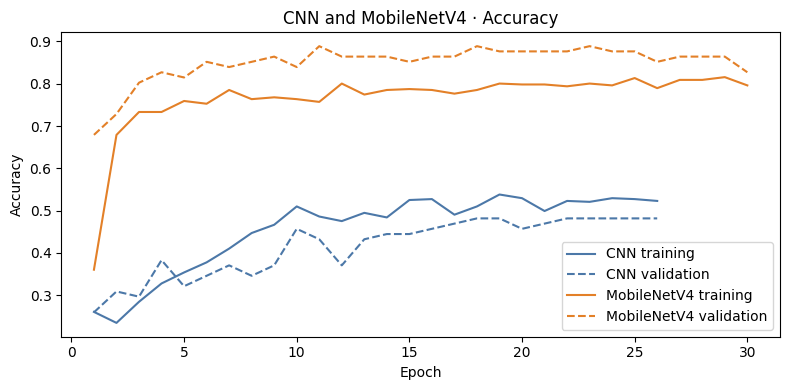

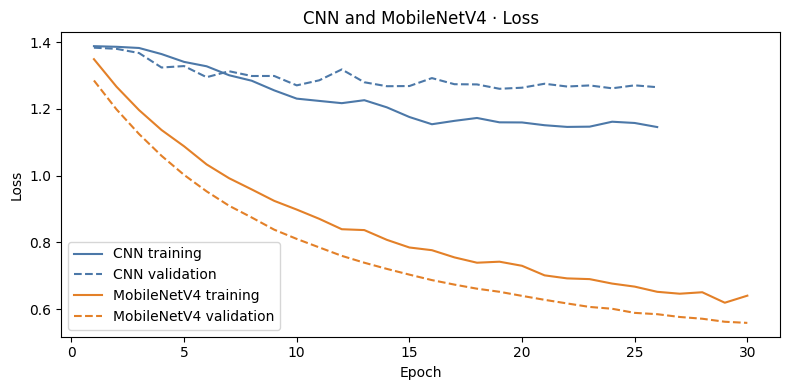

In [12]:
histories = {'CNN': history_cnn, 'MobileNetV4': history_transfer}
for metric in ['accuracy', 'loss']:
    fig, ax = plt.subplots(figsize=(8, 4))
    for (name, history), color in zip(histories.items(), ['#4C78A8', '#E38028']):
        epochs = np.arange(1, len(history.history[metric]) + 1)
        ax.plot(epochs, history.history[metric], color=color, label=f'{name} training')
        ax.plot(epochs, history.history[f'val_{metric}'], '--', color=color, label=f'{name} validation')
    ax.set(xlabel='Epoch', ylabel=metric.capitalize(), title=f'CNN and MobileNetV4 · {metric.capitalize()}')
    ax.legend()
    plt.tight_layout()
    plt.show()

In [13]:
def calculate_metrics(true, predicted):
    precision, recall, f1, _ = precision_recall_fscore_support(true, predicted, labels=np.arange(N_CLASSES), average='macro', zero_division=0)
    return {
        'accuracy': accuracy_score(true, predicted),
        'precision_macro': precision,
        'recall_macro': recall,
        'f1_macro': f1
    }

In [14]:
models = {'CNN': deep_cnn, 'MobileNetV4': transfer_model}
validation_predictions = {}
test_predictions = {}
test_probabilities = {}

for name, model in models.items():
    validation_predictions[name] = model.predict(val_ds, verbose=0).argmax(axis=1)
    probabilities = model.predict(test_ds, verbose=0)
    test_probabilities[name] = probabilities
    test_predictions[name] = probabilities.argmax(axis=1)

rows = []
for split, actual, predictions in [
    ('Validation', y_val, validation_predictions),
    ('Test', y_test, test_predictions)
]:
    for name, predicted in predictions.items():
        rows.append({'split': split, 'model': name, 'correct': int(np.sum(actual == predicted)),
                     'total': len(actual), **calculate_metrics(actual, predicted)})

comparison = pd.DataFrame(rows).set_index(['split', 'model'])
display(comparison.round(4))

correct  total  accuracy  precision_macro  \
split      model                                                    
Validation CNN               39     81    0.4815           0.5013   
           MobileNetV4       67     81    0.8272           0.8395   
Test       CNN               34     81    0.4198           0.4157   
           MobileNetV4       59     81    0.7284           0.7469   

                        recall_macro  f1_macro  
split      model                                
Validation CNN                0.4840    0.4621  
           MobileNetV4        0.8228    0.8224  
Test       CNN                0.4173    0.3858  
           MobileNetV4        0.7262    0.7181

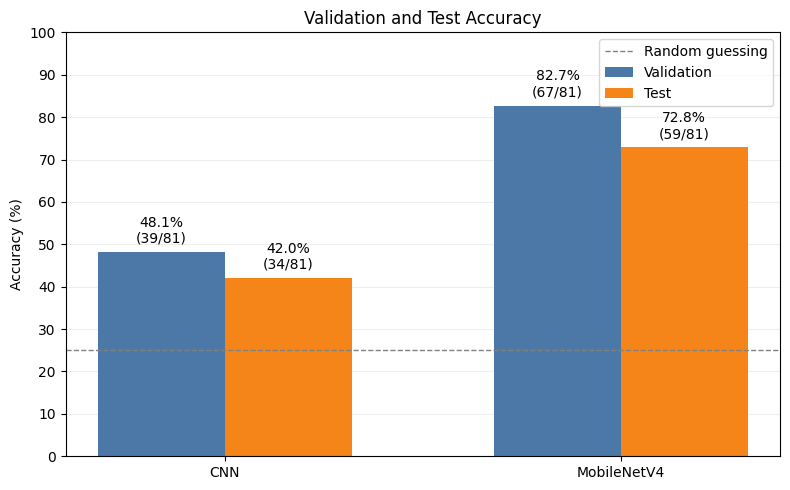

In [15]:
model_names = list(test_predictions)
val_correct = np.array([
    np.sum(validation_predictions[name] == y_val) for name in model_names
])

test_correct = np.array([
    np.sum(test_predictions[name] == y_test)
    for name in model_names
])

x = np.arange(len(model_names))
width = 0.32

fig, ax = plt.subplots(figsize=(8, 5))

for offset, correct, total, label, color in [
    (-width / 2, val_correct, len(y_val), 'Validation', '#4C78A8'),
    ( width / 2, test_correct, len(y_test), 'Test', '#F58518')
]:
    accuracy = correct / total * 100
    bars = ax.bar(
        x + offset,
        accuracy,
        width,
        label=label,
        color=color
    )

    for bar, value, count in zip(bars, accuracy, correct):
        inside = value >= 90
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            value - 2 if inside else value + 1.5,
            f'{value:.1f}%\n({count}/{total})',
            ha='center',
            va='top' if inside else 'bottom',
            fontsize=10
        )

ax.axhline(
    100 / N_CLASSES,
    color='gray',
    linestyle='--',
    linewidth=1,
    label='Random guessing'
)

ax.set_xticks(x)
ax.set_xticklabels(model_names)
ax.set_ylim(0, 100)
ax.set_yticks(np.arange(0, 101, 10))
ax.set_ylabel('Accuracy (%)')
ax.set_title('Validation and Test Accuracy')
ax.legend(loc='upper right')
ax.grid(axis='y', alpha=0.2)
ax.set_axisbelow(True)

plt.tight_layout()
plt.show()

In [16]:
for name, predicted in test_predictions.items():
    print('\n' + '=' * 60)
    print(name)
    print('=' * 60)

    print(classification_report(
        y_test,
        predicted,
        labels=np.arange(N_CLASSES),
        target_names=CLASS_NAMES,
        digits=4,
        zero_division=0
    ))


CNN
              precision    recall  f1-score   support

     bottles     0.4000    0.1000    0.1600        20
        cups     0.4800    0.6000    0.5333        20
        pens     0.3939    0.6190    0.4815        21
    scissors     0.3889    0.3500    0.3684        20

    accuracy                         0.4198        81
   macro avg     0.4157    0.4173    0.3858        81
weighted avg     0.4154    0.4198    0.3870        81


MobileNetV4
              precision    recall  f1-score   support

     bottles     0.8182    0.4500    0.5806        20
        cups     0.8000    0.8000    0.8000        20
        pens     0.6552    0.9048    0.7600        21
    scissors     0.7143    0.7500    0.7317        20

    accuracy                         0.7284        81
   macro avg     0.7469    0.7262    0.7181        81
weighted avg     0.7458    0.7284    0.7186        81



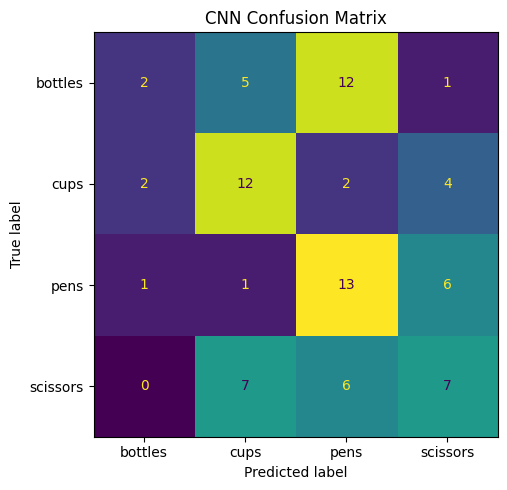

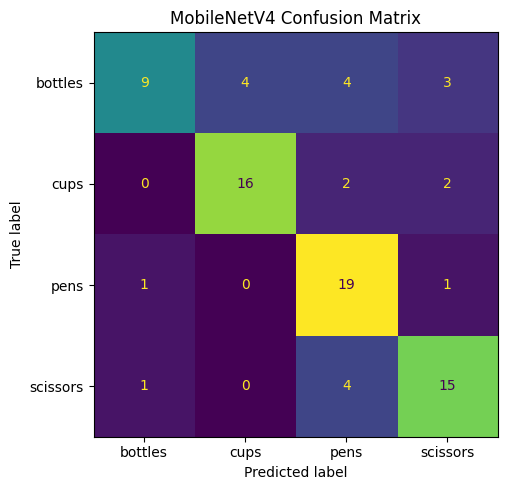

In [17]:
for name, predicted in test_predictions.items():
    plt.figure(figsize=(6, 5))

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predicted,
        labels=np.arange(N_CLASSES),
        display_labels=CLASS_NAMES,
        colorbar=False,
        ax=plt.gca()
    )

    plt.title(f'{name} Confusion Matrix')
    plt.tight_layout()
    plt.show()

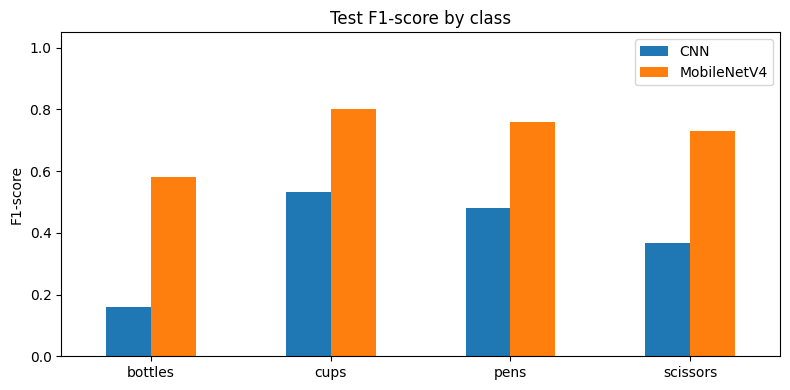

In [18]:
per_class_f1 = {}
for name, predicted in test_predictions.items():
    report = classification_report(y_test, predicted, labels=np.arange(N_CLASSES),
                                   target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    per_class_f1[name] = [report[class_name]['f1-score'] for class_name in CLASS_NAMES]

pd.DataFrame(per_class_f1, index=CLASS_NAMES).plot.bar(
    figsize=(8, 4), rot=0, ylim=(0, 1.05), ylabel='F1-score', title='Test F1-score by class'
)
plt.tight_layout()
plt.show()

### Examples of correct and incorrect predictions

Correct predictions: 59 / 81
Incorrect predictions: 22 / 81

Examples of Correct Predictions


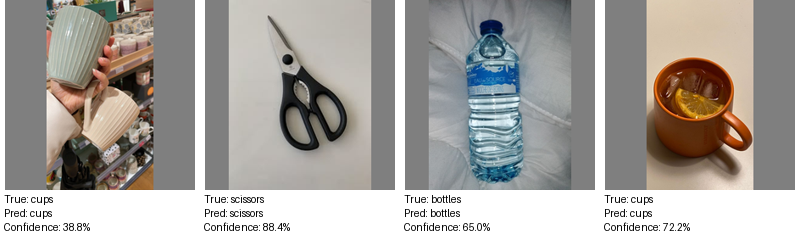


Examples of Incorrect Predictions


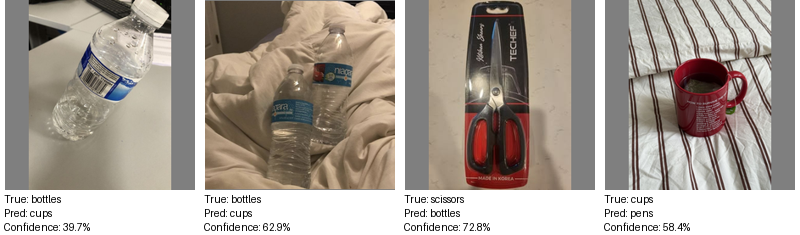

In [19]:
model_name = 'MobileNetV4'  # Change to 'CNN' to inspect the baseline.
predictions = test_predictions[model_name]
probabilities = test_probabilities[model_name]

correct_indices = np.flatnonzero(predictions == y_test)
incorrect_indices = np.flatnonzero(predictions != y_test)

print(f'Correct predictions: {len(correct_indices)} / {len(y_test)}')
print(f'Incorrect predictions: {len(incorrect_indices)} / {len(y_test)}')

rng = np.random.default_rng(SEED)

groups = [
    ('Examples of Correct Predictions', correct_indices),
    ('Examples of Incorrect Predictions', incorrect_indices)
]

for heading, indices in groups:
    print(f'\n{heading}')

    if len(indices) == 0:
        print('No examples available.')
        continue

    selected = rng.choice(
        indices,
        size=min(4, len(indices)),
        replace=False
    )

    titles = [
        f'True: {CLASS_NAMES[y_test[i]]}\n'
        f'Pred: {CLASS_NAMES[predictions[i]]}\n'
        f'Confidence: {probabilities[i, predictions[i]] * 100:.1f}%'
        for i in selected
    ]

    show_images(
        X_test[selected],
        titles,
        cols=4
    )

## Save both models
Each `.keras` file includes the architecture, preprocessing and trained weights. The class names are saved in prediction order. To classify a new photo, apply `prepare_image` and pass a batch of raw RGB pixels to the restored model.

In [20]:
save_dir = PROJECT_DIR / 'runs' / 'keras_a2'
save_dir.mkdir(parents=True, exist_ok=True)
for name, model in [('baseline_cnn', deep_cnn), ('mobilenetv4_transfer', transfer_model)]:
    path = save_dir / f'{name}.keras'
    model.save(path)
    restored = keras.models.load_model(path, compile=False)
    np.testing.assert_allclose(restored(X_test[:1], training=False).numpy(),
                               model(X_test[:1], training=False).numpy(), rtol=1e-5, atol=1e-6)
    print(f'Saved and checked {path.name}')

(save_dir / 'class_names.json').write_text(json.dumps(CLASS_NAMES, indent=2), encoding='utf-8')
comparison.to_csv(save_dir / 'metrics.csv')
print('Saved under the project folder:', save_dir.relative_to(PROJECT_DIR))

Saved and checked baseline_cnn.keras
Saved and checked mobilenetv4_transfer.keras
Saved under the project folder: runs/keras_a2
